# 05. Quality control: this re-analysis against the original analysis

The original study (Kim et al. 2022) used Proteome Discoverer 2.2 with SEQUEST-HT and a 2014 UniProt database.
This notebook checks that the open workflow used here (FragPipe 24.0) reproduces it: how many identifications, how many shared genes, and how well the quantities agree donor by donor.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RES = ROOT / "results"
SEARCH = ROOT / "results_large" / "search_ALL_SETS"
COL = {"control": "#2a78d6", "suicide": "#eb6834"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
meta = pd.read_csv(RES / "sample_map.tsv", sep="\t")
samples = meta["sample"].tolist()
is_suicide = (meta["group"] == "suicide").to_numpy()

## Identifications

In [2]:
rows = []
for s in range(1, 5):
    log = (SEARCH / f"SET_{s}" / "filter.log").read_text(encoding="utf-8", errors="replace")
    m = re.search(r"Final report numbers.*?ions=(\d+) peptides=(\d+) proteins=(\d+) psms=(\d+)", log)
    rows.append((f"SET_{s}", int(m.group(4)), int(m.group(2)), int(m.group(3))))
ident = pd.DataFrame(rows, columns=["TMT set", "PSMs", "peptides", "protein groups"]).set_index("TMT set")
ident.loc["all sets (sum of PSMs)"] = [ident["PSMs"].sum(), np.nan, np.nan]
ident.to_csv(RES / "qc_identifications.tsv", sep="\t")
ident

,PSMs,peptides,protein groups
TMT set,,,
SET_1,650046.0,120613.0,10876.0
SET_2,626963.0,117938.0,10871.0
SET_3,629610.0,122727.0,11007.0
SET_4,611920.0,118481.0,10920.0
all sets (sum of PSMs),2518539.0,NaN,NaN


In [3]:
ours = pd.read_csv(SEARCH / "tmt-report" / "ratio_gene_MD.tsv", sep="\t").set_index("Index")
ours = ours[~ours["ProteinID"].str.split(";").apply(lambda ids: all(i.startswith("Cont_") for i in ids))]
auth = pd.read_excel(ROOT / "data_external" / "Kim2022_MOESM2_ESM.xlsx", sheet_name="Table S2", header=None, skiprows=3)
a = auth.iloc[:, 16:52].apply(pd.to_numeric, errors="coerce"); a.columns = samples
a = np.log2(a.where(a > 0)); a.index = auth[3].astype(str)
a = a[(a.index != "nan") & ~a.index.duplicated()]
o = ours[samples]
both = sorted(set(o.index) & set(a.index))
summary = pd.Series({
    "genes quantified, this re-analysis": len(o),
    "genes quantified in all 36 donors, this re-analysis": int(o.notna().all(axis=1).sum()),
    "protein groups, original analysis": len(auth),
    "gene names, original analysis": len(a),
    "genes in both": len(both),
    "share of original genes recovered (%)": round(100 * len(both) / len(a), 1),
})
summary.to_csv(RES / "qc_gene_overlap.tsv", sep="\t", header=False)
summary

genes quantified, this re-analysis                     10236.0
genes quantified in all 36 donors, this re-analysis     8384.0
protein groups, original analysis                       9802.0
gene names, original analysis                           9083.0
genes in both                                           8450.0
share of original genes recovered (%)                     93.0
dtype: float64

## Agreement of quantities

Both analyses express abundance relative to the pooled reference channel. For every gene quantified in all donors by both, the 36 values are correlated between the two analyses.

In [4]:
A = a.loc[both]; O = o.loc[both]
ok = A.notna().all(axis=1) & O.notna().all(axis=1)
A, O = A[ok], O[ok]
Ac = A.sub(A.mean(axis=1), axis=0); Oc = O.sub(O.mean(axis=1), axis=0)
r_gene = (Ac * Oc).sum(axis=1) / np.sqrt((Ac ** 2).sum(axis=1) * (Oc ** 2).sum(axis=1))
fc_a = A.loc[:, is_suicide].mean(axis=1) - A.loc[:, ~is_suicide].mean(axis=1)
fc_o = O.loc[:, is_suicide].mean(axis=1) - O.loc[:, ~is_suicide].mean(axis=1)
r_fc = stats.pearsonr(fc_a, fc_o)[0]
print(f"{ok.sum()} genes complete in both analyses")
print(f"per-gene correlation across donors: median r = {r_gene.median():.2f}; {100 * (r_gene > 0.5).mean():.0f}% of genes with r > 0.5")
print(f"suicide-control difference (log2), original vs re-analysis: r = {r_fc:.2f}")

7099 genes complete in both analyses
per-gene correlation across donors: median r = 0.75; 84% of genes with r > 0.5
suicide-control difference (log2), original vs re-analysis: r = 0.77


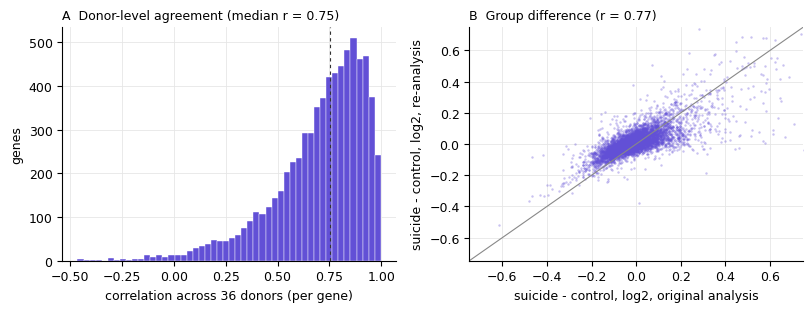

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(8.2, 3.2))
ax[0].hist(r_gene, bins=50, color="#6250d6", edgecolor="white", linewidth=0.3)
ax[0].axvline(r_gene.median(), color="#333333", lw=0.8, ls=(0, (3, 3)))
ax[0].set_xlabel("correlation across 36 donors (per gene)"); ax[0].set_ylabel("genes")
ax[0].set_title(f"A  Donor-level agreement (median r = {r_gene.median():.2f})", fontsize=9, loc="left")
ax[1].scatter(fc_a, fc_o, s=3, color="#6250d6", alpha=0.35, linewidths=0)
lim = np.percentile(np.abs(np.r_[fc_a, fc_o]), 99.8)
ax[1].plot([-lim, lim], [-lim, lim], color="#888888", lw=0.8)
ax[1].set_xlim(-lim, lim); ax[1].set_ylim(-lim, lim)
ax[1].set_xlabel("suicide - control, log2, original analysis"); ax[1].set_ylabel("suicide - control, log2, re-analysis")
ax[1].set_title(f"B  Group difference (r = {r_fc:.2f})", fontsize=9, loc="left")
for x in ax:
    x.grid(color="#e6e6e6", lw=0.6); x.set_axisbelow(True)
fig.tight_layout(); fig.savefig(RES / "fig_qc_agreement.png", dpi=300); plt.show()

## Conclusion

The re-analysis recovers the large majority of the genes of the original analysis and reproduces their donor-level quantities, with a different search engine, a different database and current software.
Counts of "protein groups" are not compared directly, because the two databases differ (isoform entries in the original, variant entries here); genes are the common unit.